Ion counting experiments measure the excess of ions adsorbed to a molecule with respect to bulk.

In [1]:
import seaborn as sns

import MDAnalysis as mda
from tqdm.auto import tqdm
import pandas as pd

import numpy as np

from mg_sampling import PROJECT_DIR
from mg_sampling.tools import read_plumed
import itertools


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
compute = False

In [3]:
if compute:
    results = []

    methods = ['replex', 'plain_md']
    systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
    forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
    replicates = range(2)
    replicas = range(8)

    radius = 20
    names = ['OW', 'MG', 'NA', 'CL']

    for method, sys, ff, replicate, rep in itertools.product(methods, systems, forcefields, replicates, replicas):
        path = PROJECT_DIR / f'{method}/{sys}/{ff}/replicate{replicate}/rep{rep+replicate*8:02d}'
        if not path.exists():
            continue
        
        u = mda.Universe(path / 'input.gro', path / 'run.xtc')

        if method == 'replex':
            reptemp = read_plumed(path / f'bias.COLVAR.{rep}')['bias.index'].astype(int)
            frames = (reptemp == 0).to_numpy()[::10]
            assert len(frames) == len(u.trajectory)
        else:
            frames = np.ones(len(u.trajectory), dtype=bool)
        sel = np.zeros(len(u.trajectory), dtype=bool)
        sel[::10] = True
        frames = frames & sel

        bulk_sels = {
            name: u.select_atoms(f"name {name}").select_atoms(f"not around {radius} global name P", updating=True)
            for name in names
        }

        for ts in tqdm(u.trajectory[frames]):
            for name in names:
                results.append(
                    {
                        'sim': f"{method}_{sys}_{ff}",
                        'time': ts.time,
                        'name': name,
                        'n_bulk': len(bulk_sels[name]),
                        'replicate': replicate if method == 'replex' else rep
                    }
                )
                
    df = pd.DataFrame(results).set_index(['sim', 'time', 'name', 'replicate']).sort_index()
    df['c_bulk'] = 1000 * df['n_bulk'] / df['n_bulk'].loc[:, :, 'OW'] * 55.5
    df.to_csv('ion_count_bulk.csv')
else:
    df = pd.read_csv('ion_count_bulk.csv', na_filter=False)

In [4]:
sim_labels = {
    "plain_md_7ez0_mMg_tip3p": "μMg (MD)",
    "plain_md_7ez0_nMg_tip3p": "nMg (MD)",
    "plain_md_7ez0_nMg_tip3p_soft": "nMg (MD-soft)",
    "plain_md_7ez0_noion_nMg_tip3p": "nMg (MD-denovo)",
    "plain_md_7ez0_nomg_mMg_tip3p": "no-Mg (MD)",
    "replex_7ez0_mMg_tip3p": "μMg (REx)",
    "replex_7ez0_noion_mMg_tip3p": "μMg (REx-denovo)",
}

eq_times = {
    "plain_md_7ez0_mMg_tip3p": 150000,
    "plain_md_7ez0_nMg_tip3p": 150000,
    "plain_md_7ez0_nMg_tip3p_soft": 150000,
    "plain_md_7ez0_noion_nMg_tip3p": 150000,
    "plain_md_7ez0_nomg_mMg_tip3p": 100000,
    "replex_7ez0_mMg_tip3p": 50000,
    "replex_7ez0_noion_mMg_tip3p": 50000,
}


df['label'] = df['sim'].map(sim_labels)
df['eq_time'] = df['sim'].map(eq_times)

In [5]:
df

,sim,time,name,replicate,n_bulk,c_bulk,label,eq_time
0,plain_md_7ez0_mMg_tip3p,0.0,CL,0,80,80.554447,μMg (MD),150000
1,plain_md_7ez0_mMg_tip3p,0.0,CL,1,81,81.406298,μMg (MD),150000
2,plain_md_7ez0_mMg_tip3p,0.0,CL,2,83,83.613163,μMg (MD),150000
3,plain_md_7ez0_mMg_tip3p,0.0,CL,3,85,85.637265,μMg (MD),150000
4,plain_md_7ez0_mMg_tip3p,0.0,CL,4,79,77.867761,μMg (MD),150000
...,...,...,...,...,...,...,...,...
92971,replex_7ez0_noion_mMg_tip3p,200000.0,MG,1,11,10.813156,μMg (REx-denovo),50000
92972,replex_7ez0_noion_mMg_tip3p,200000.0,NA,0,58,57.003719,μMg (REx-denovo),50000
92973,replex_7ez0_noion_mMg_tip3p,200000.0,NA,1,54,53.082768,μMg (REx-denovo),50000
92974,replex_7ez0_noion_mMg_tip3p,200000.0,OW,0,56470,55500.000000,μMg (REx-denovo),50000


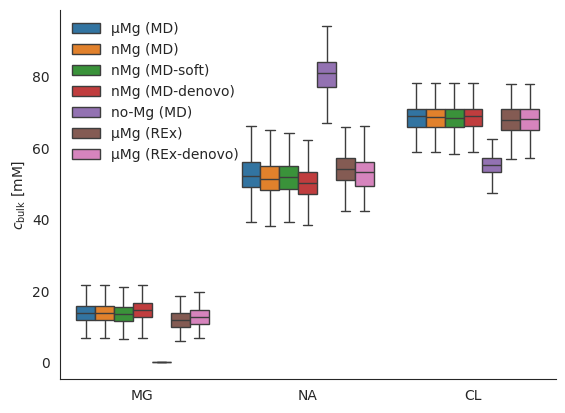

In [15]:
sns.set_style("white")

ax = sns.boxplot(
    df.reset_index().query('time > eq_time and name != "OW"'),
    x = 'name',
    y = 'c_bulk',
    hue = 'label',
    order = ['MG', 'NA', 'CL'],
    showfliers = False,
)
ax.set_xlabel('')
ax.set_ylabel(r'$c_\mathrm{bulk}$ [mM]')
ax.get_legend().set_title(None)
ax.get_legend().set_frame_on(False)
sns.move_legend(ax,  "upper left")
sns.despine()
ax.get_figure().savefig('figures/bulk_concentrations.pdf')